In [4]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import find_peaks
import datetime
import glob
import joblib
import shutil
import umap

sys.path.insert(0, "cellular_cycle") # add path to the model

from cell_cycle_death_model import model

# should examine these functions to determine which are best to use (overlapping functionality)
from model_fxns import minmax_scale, stack_sliding_window, calc_minmax, load_sim_output, load_norm_data


# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
SAVE_DIR.mkdir(exist_ok=True)

OVERWRITE = False # Overwrite existing simulation files
SET_JPARAM = False # Set the parameter values for the simulation using PSO-optimized values

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

ORIG_SIM_DIR = Path(SAVE_DIR,'orig_sims')
DOWNLOAD = False # set to true to automatically download the original data from Dropbox
GENERATE_UMAP = False # Generate UMAP plots for the simulation output

sys_type = sys.platform

### Detect computer system
NOTE: UMAP reducer files are dependent on processor, OS and package versions

### Load Data

These files were generated using original parameters and used to produce UMAP for the manuscript (

**Output files from [03_Stoch_sims_for_UMAP.ipynb](03_Stoch_sims_for_UMAP.ipynb)**:
```
ODE_sim_DMSO_stiff_000_orig.csv
ODE_sim_DMSO_stiff_029_orig.csv
ODE_sim_DMSO_stiff_049_orig.csv
ODE_sim_DMSO_stiff_074_orig.csv
ODE_sim_DMSO_stiff_099_orig.csv
ODE_sim_ERL_stiff_000_orig.csv
ODE_sim_ERL_stiff_029_orig.csv
ODE_sim_ERL_stiff_049_orig.csv
ODE_sim_ERL_stiff_074_orig.csv
ODE_sim_ERL_stiff_099_orig.csv
stoch_sim_DMSO_stiff_000_orig.csv
stoch_sim_DMSO_stiff_029_orig.csv
stoch_sim_DMSO_stiff_049_orig.csv
stoch_sim_DMSO_stiff_074_orig.csv
stoch_sim_DMSO_stiff_099_orig.csv
stoch_sim_ERL_stiff_000_orig.csv
stoch_sim_ERL_stiff_029_orig.csv
stoch_sim_ERL_stiff_049_orig.csv
stoch_sim_ERL_stiff_074_orig.csv
stoch_sim_ERL_stiff_099_orig.csv
```

#### NOTE: Variations in UMAP output will exist due to use of different stochastic simulations or generation on different platforms


In [5]:
if DOWNLOAD and not ORIG_SIM_DIR.exists() or len(list(ORIG_SIM_DIR.glob('*.csv'))) == 0:
    print('Downloading original stochastic simulation data')
    LOCALDIR = Path(ORIG_SIM_DIR.parts[-1])
    if not LOCALDIR.exists():
        os.mkdir(LOCALDIR)
    if not ORIG_SIM_DIR.exists():
        os.mkdir(ORIG_SIM_DIR)

    if sys_type == 'win32':
        new_url = 'https://www.dropbox.com/scl/fi/j4c3d2ypdws50lks45lag/orig_sims.zip?rlkey=evill8yurm6dzq7dnf03036vf&dl=1'
        !curl -L -o orig_sims.zip $new_url
        !mv orig_sims.zip $SAVE_DIR
        !unzip $SAVE_DIR/'orig_sims.zip' -d $SAVE_DIR
        os.remove(SAVE_DIR / 'orig_sims.zip')
        shutil.rmtree(SAVE_DIR / '__MACOSX')
    else:
        !wget 'https://www.dropbox.com/scl/fi/j4c3d2ypdws50lks45lag/orig_sims.zip?rlkey=evill8yurm6dzq7dnf03036vf&dl=1' -O orig_sims.zip
        # !mv orig_sims.zip $ORIG_SIM_DIR
        !unzip 'orig_sims.zip' -d $SAVE_DIR
        os.remove('orig_sims.zip')
        shutil.rmtree(SAVE_DIR / '__MACOSX')
        os.rmdir('orig_sims')


In [6]:
exp_stiff_vals = ['000','049','099']

In [7]:
if SET_JPARAM:
    stoch_filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and 'pso_2' in f and not 'orig' in f]
    stoch_filenames.sort()
else:
    stoch_filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_stiff_' in f and 'orig' in f]
    stoch_filenames.sort()

if DOWNLOAD:
    stoch_filenames = [str(Path(ORIG_SIM_DIR, f)) for f in os.listdir(ORIG_SIM_DIR) if '.csv' in f and 'stoch_sim' in f]
else:
    stoch_filenames = globals()[f'stoch_filenames']

stoch_filenames.sort()
stoch_filenames

[WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_099_orig.csv')]

In [8]:
stoch_filenames_umap = [f for f in stoch_filenames if any([x in str(f) for x in exp_stiff_vals])]
stoch_filenames_umap

[WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_ERL_stiff_099_orig.csv')]

In [9]:
ode_filenames = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames]
ode_filenames

[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_029_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_074_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_099_orig.csv')]

In [10]:
ode_filenames_umap = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames_umap]
ode_filenames_umap

[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_ERL_stiff_099_orig.csv')]

### Set UMAP parameters

In [12]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 5

### Define UMAP reducer filename

In [13]:
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240730'
    r_dbpath = 'https://www.dropbox.com/scl/fi/pvx434xg8e391bil5b8wd/reducer_mac_0.1_0.1_4_0.5.sav?rlkey=nuwm98ld3guyukz14a9m6ewu7&dl=1'
if sys_type == 'win32': 
    sys_name = 'win'
    r_path_date = '20240820'
    r_dbpath = 'https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1'
if sys_type == 'linux': 
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

if SET_JPARAM:
    r_name = f'reducerPSO_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'
else:
    r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [14]:
r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [15]:
r_path = Path(SAVE_DIR,'UMAP',r_name)

%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=C:\Users\olesk\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1


In [16]:
# max_prots, min_prots = calc_minmax(stoch_filenames, ode_filenames)
max_prots, min_prots = calc_minmax(stoch_filenames_umap + ode_filenames_umap)

In [17]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [18]:
# experimental conditions only
[all_prot_umap, all_prot_ode_umap, all_time_umap, all_time_at_umap] = load_norm_data(stoch_filenames_umap, ode_filenames_umap, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)

# Conditions identified in Lyapunov analysis
[all_prot_lyap, all_prot_ode_lyap, all_time_lyap, all_time_at_lyap] = load_norm_data(stoch_filenames, ode_filenames, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


#### Confirmation of protein time course shape

In [24]:

assert all_prot_umap.shape == (239958, 720), all_prot_umap.shape == (399930, 720) # 

#### Confirmation global max and min vals

In [25]:

assert [np.amax(all_prot_umap), np.amin(all_prot_umap)] == [1.0,0.0]

### Calculate IMTs

In [21]:
t = np.linspace(0, 20000, 200001)

In [22]:
def getIMT(prot):
    peaks_cdc, _ = find_peaks(prot[:,int((win_len*17+win_len/2)-1)], prominence=0.5, distance=100)
    IMTs = [t[y] - t[x] for x, y in zip(peaks_cdc, peaks_cdc[1:])]
    
    return IMTs

In [23]:
all_IMTs = []
len_IMTs = []
for num in range(6):
    IMTs = getIMT(all_prot_umap[num*len_prot:(num+1)*len_prot,:])
    all_IMTs.append(IMTs)
    len_IMTs.append(len(IMTs))


NameError: name 'len_prot' is not defined

In [71]:
IMTcount_path = Path(SAVE_DIR, 'IMTcount_param_orig.csv')
np.savetxt(IMTcount_path, len_IMTs, delimiter=',')

### Get reducer (model for UMAP embedding)

In [26]:
if GENERATE_UMAP:
    print(f'Generating UMAP with {neighbs} neighbors and {min_d} min_dist')
    reducer = umap.UMAP(
                        n_neighbors=neighbs,
                        min_dist=min_d,
                        n_components=2,
                        metric='euclidean',
                        random_state=RANDOM_STATE,
                        low_memory=True        
                        ).fit(all_prot_umap)
else:
    if not r_path.exists():
        print(f'Could not find {r_path}; downloading from Dropbox: {r_dbpath}')
        !wget -O $R_PATH $R_DBPATH
    print(f'Loading reducer from {r_path}')
    reducer = joblib.load(r_path)

Loading reducer from C:\Users\olesk\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav


### Generate embedding of stochastic trajectories

In [27]:
embedding_all_prot = reducer.transform(all_prot_lyap)

In [28]:
len(embedding_all_prot)

399930

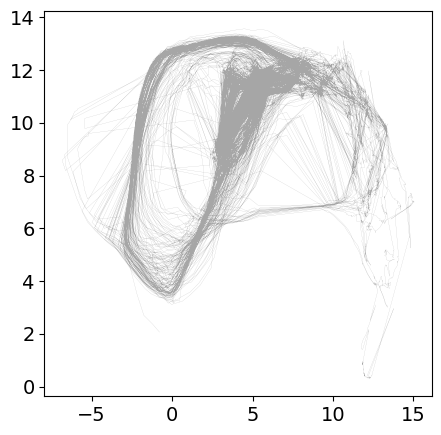

In [39]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(stoch_filenames))
trk_len_ode = int(len(embedding_all_prot)/len(stoch_filenames))

pos = 5

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7, c='gray')



In [21]:
# Save the UMAP object
if GENERATE_UMAP:
    reducer_filename = Path(SAVE_DIR, 'UMAP', r_name)
    if not Path(SAVE_DIR,'UMAP').exists():
        os.mkdir(Path(SAVE_DIR,'UMAP'))
    if not reducer_filename.exists() or OVERWRITE:
        print(f'Saving reducer to {reducer_filename}')
        joblib.dump(reducer, reducer_filename)

Saving reducer to C:\Users\olesk\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav


In [40]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_ode_lyap)/len(ode_filenames)
sp = 1
for n in range(len(ode_filenames)):
    tmp = all_prot_ode_lyap[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [41]:
all_prot_tmp_ode_ab.shape

(20000, 720)

### Generate embedding of ODE solutions

In [42]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [43]:
# Save all the outputs
if SET_JPARAM:
    if  not Path(SAVE_DIR, f'all_embedding_ode_conds_psoparams_{sys_name}.sav').exists() or OVERWRITE:
        print(f'Saving UMAP embeddings for pso parameters on a {sys_name} system.')
        joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_psoparams_{sys_name}.sav'))
        joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_psoparams_{sys_name}.sav'))
        joblib.dump(all_prot_lyap, Path(SAVE_DIR, f'all_prot_stoch_conds_psoparams_{sys_name}.sav'))
        joblib.dump(all_time_lyap, Path(SAVE_DIR, f'all_time_tmp_{sys_name}_psoparams.sav'))
        joblib.dump(all_time_at_lyap, Path(SAVE_DIR, f'all_time_at_tmp_{sys_name}_psoparams.sav'))
else:
    if  not Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_orig.sav').exists() or OVERWRITE:
        print(f'Saving UMAP embeddings for original parameters on a {sys_name} system.')
        joblib.dump(embedding_all_prot_ode, Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_orig.sav'))
        joblib.dump(embedding_all_prot, Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_orig.sav'))
        joblib.dump(all_prot_lyap, Path(SAVE_DIR, f'all_prot_stoch_conds_{sys_name}_orig.sav'))
        joblib.dump(all_time_lyap, Path(SAVE_DIR, f'all_time_tmp_{sys_name}_orig.sav'))
        joblib.dump(all_time_at_lyap, Path(SAVE_DIR, f'all_time_at_tmp_{sys_name}_orig.sav'))

Saving UMAP embeddings for pso parameters on a win system.
